# EMA fixed-point model, explored

`ema_fixed.py` runs the same recursion as `ema_float.py`, but through `qformat.py`'s quantize/saturate at an explicit bit width. The input/output live at `Q(int_bits).(frac_bits)`; the accumulator is kept wider, at `frac_bits + guard_bits`, and only rounded down to the native width on readout.

This notebook reproduces the exact hardware problem CLAUDE.md flags: at a long tau and a high sample rate, alpha gets tiny, and without extra accumulator precision the filter's output never moves at all.

In [4]:
import sys
sys.path.insert(0, '../models')

import numpy as np
import matplotlib.pyplot as plt
from ema_float import alpha_from_tau, ema_filter
from ema_fixed import ema_filter_fixed, required_guard_bits

## The stall: tau=1s at 1 MSa/s

`alpha = 1 - exp(-Ts/tau)` works out to about `1e-6` here. With 15 fractional bits and no guard bits (`guard_bits=0`), the smallest representable step is `2^-15 ~ 3e-5` - far bigger than `alpha * diff` ever gets, since `diff` is bounded to roughly `[-2, 2]` in this format. Every increment rounds to zero.

alpha = 1.000e-06


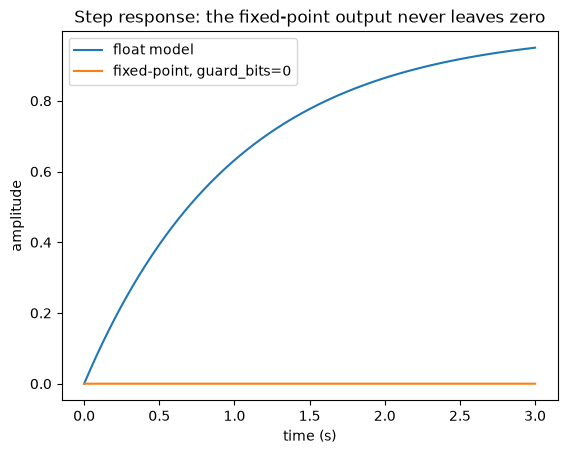

In [5]:
Ts = 1e-6
tau = 1.0
alpha = alpha_from_tau(tau, Ts)
print(f'alpha = {alpha:.3e}')

n_samples = 3_000_000  # a few tau worth, at 1 MSa/s
x = np.ones(n_samples)
t = np.arange(n_samples) * Ts

y_float = ema_filter(x, alpha)
y_stalled = ema_filter_fixed(x, alpha, int_bits=1, frac_bits=15, guard_bits=0)

plt.plot(t, y_float, label='float model')
plt.plot(t, y_stalled, label='fixed-point, guard_bits=0')
plt.xlabel('time (s)')
plt.ylabel('amplitude')
plt.legend()
plt.title('Step response: the fixed-point output never leaves zero')
plt.show()

## The fix: enough guard bits

The naive fix is "enough guard bits that the *first* increment doesn't underflow." That's not sufficient: as `y` approaches `x`, `diff = x - y` keeps shrinking, so `alpha * diff` keeps shrinking too, and it will underflow again partway through convergence - the filter stalls at whatever value that was, not at the true final value. `required_guard_bits` accounts for this properly: it sizes the accumulator so the filter keeps making progress until `diff` is within one *output* LSB, since anything finer than that is invisible at the output anyway.

guard_bits needed = 20 (accumulator: Q1.35)


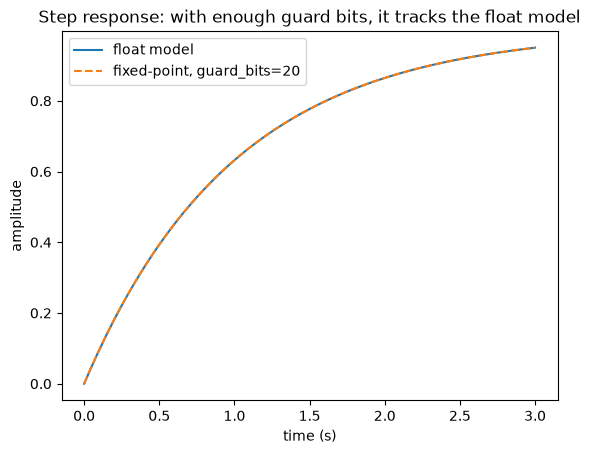

max error vs. float model: 4.30e-05


In [6]:
frac_bits = 15
guard_bits = required_guard_bits(alpha, frac_bits)
print(f'guard_bits needed = {guard_bits} (accumulator: Q1.{frac_bits + guard_bits})')

y_fixed = ema_filter_fixed(x, alpha, int_bits=1, frac_bits=frac_bits, guard_bits=guard_bits)

plt.plot(t, y_float, label='float model')
plt.plot(t, y_fixed, '--', label=f'fixed-point, guard_bits={guard_bits}')
plt.xlabel('time (s)')
plt.ylabel('amplitude')
plt.legend()
plt.title('Step response: with enough guard bits, it tracks the float model')
plt.show()

print(f'max error vs. float model: {np.max(np.abs(np.array(y_fixed) - y_float)):.2e}')